In [104]:
import xml.etree.ElementTree as ET
import cv2
import matplotlib.pyplot as plt
from pathlib import Path
import numpy as np
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix
import json

Read our xml data for one picture

In [44]:
xml_path="../data/train/00001.xml"
tree = ET.parse(xml_path)
root=tree.getroot()

filename = root.find("filename").text
print("Image:", filename)

for obj in root.findall("object"):

    character = obj.find("name").text

    box = obj.find("bndbox")

    xmin = int(box.find("xmin").text)
    ymin = int(box.find("ymin").text)
    xmax = int(box.find("xmax").text)
    ymax = int(box.find("ymax").text)

    print(character, xmin, ymin, xmax, ymax)

Image: for_xml_2811.jpg
1 59 56 101 171
2 96 63 149 181
ز 157 97 211 199
8 219 113 273 216
1 285 124 325 245
6 318 141 382 242
1 396 177 435 282
1 442 192 488 295


load our image (one image for test)

In [45]:
image = cv2.imread("../data/train/00001.jpg")

find characters in our one images

In [46]:
characters = []

for obj in root.findall("object"):

    label = obj.find("name").text

    box = obj.find("bndbox")

    xmin = int(box.find("xmin").text)
    ymin = int(box.find("ymin").text)
    xmax = int(box.find("xmax").text)
    ymax = int(box.find("ymax").text)

    cropped_character = image[ymin:ymax, xmin:xmax]
    characters.append((label, cropped_character))

see our characters in our one image

In [ ]:
for label, char_image in characters:

    char_rgb = cv2.cvtColor(char_image, cv2.COLOR_BGR2RGB)

    plt.imshow(char_rgb)
    plt.title(label)
    plt.axis("off")
    plt.show()

Resizing and gray scaling our one image

In [48]:
target_width = 32
target_height = 64

resized_characters = []

for label, char_image in characters:
    resized_image = cv2.resize(
        char_image,
        (target_width, target_height)
    )
    resized_characters.append((label, resized_image))

grayscale_characters = []

for label , char_image in resized_characters:
    gray_image=cv2.cvtColor(char_image,cv2.COLOR_BGR2GRAY)
    grayscale_characters.append((label, gray_image))

In [ ]:
for label , char_image in grayscale_characters:
    plt.imshow(char_image)
    plt.title(label)
    plt.axis("off")
    plt.show()

Normalization for one image

In [50]:
normalized_characters = []

for label, gray_image in grayscale_characters:
    normalized_image = gray_image.astype("float32") / 255.0
    normalized_characters.append((label, normalized_image))

label, image = normalized_characters[0]



Preprocessing Function for the Full Dataset

In [51]:
def process_plate(image_path, xml_path):
    tree = ET.parse(xml_path)
    root = tree.getroot()
    image = cv2.imread(image_path)
    characters = []

    for obj in root.findall("object"):

        label = obj.find("name").text

        box = obj.find("bndbox")

        xmin = int(box.find("xmin").text)
        ymin = int(box.find("ymin").text)
        xmax = int(box.find("xmax").text)
        ymax = int(box.find("ymax").text)

        height, width = image.shape[:2]

        xmin = max(0, min(xmin, width))
        xmax = max(0, min(xmax, width))

        ymin = max(0, min(ymin, height))
        ymax = max(0, min(ymax, height))

        if xmin >= xmax or ymin >= ymax:
            continue
        cropped_character = image[ymin:ymax, xmin:xmax]

        resized_character = cv2.resize(cropped_character,(32, 64))

        gray_character = cv2.cvtColor(resized_character,cv2.COLOR_BGR2GRAY)

        normalized_character = (
            gray_character.astype("float32") / 255.0
        )

        characters.append((label, normalized_character))

    return characters

In [52]:
train_path = Path("../data/train")
xml_files = sorted(train_path.glob("*.xml"))
print("Number of XML files:", len(xml_files))

Number of XML files: 19381


Put our training data into our training dataset

In [53]:
X_train = []
y_train = []

for xml_path in xml_files:

    image_path = xml_path.with_suffix(".jpg") # find the .jpg image that has a same name as xml_path

    characters = process_plate(
        str(image_path),
        str(xml_path)
    )

    for label, image in characters:
        X_train.append(image)
        y_train.append(label)

One problem in my dataset

In [54]:
xml_path = "../data/train/01537.xml"
image_path = "../data/train/01537.jpg"

tree = ET.parse(xml_path)
root = tree.getroot()

image = cv2.imread(image_path)

print("Image shape:", image.shape)

for obj in root.findall("object"):
    label = obj.find("name").text

    box = obj.find("bndbox")

    xmin = int(box.find("xmin").text)
    ymin = int(box.find("ymin").text)
    xmax = int(box.find("xmax").text)
    ymax = int(box.find("ymax").text)

    cropped = image[ymin:ymax, xmin:xmax]

    print(
        "Label:", label,
        "Box:", xmin, ymin, xmax, ymax,
        "Crop shape:", cropped.shape
    )

Image shape: (175, 242, 3)
Label: 1 Box: 508 1355 571 1488 Crop shape: (0, 0, 3)
Label: 3 Box: 566 1374 623 1516 Crop shape: (0, 0, 3)
Label: ت Box: 623 1444 715 1526 Crop shape: (0, 0, 3)
Label: 8 Box: 710 1420 771 1548 Crop shape: (0, 0, 3)
Label: 8 Box: 777 1444 823 1562 Crop shape: (0, 0, 3)
Label: 8 Box: 830 1448 883 1585 Crop shape: (0, 0, 3)
Label: 1 Box: 894 1484 948 1617 Crop shape: (0, 0, 3)
Label: 1 Box: 951 1499 1023 1626 Crop shape: (0, 0, 3)
Label: 4 Box: 21 49 42 101 Crop shape: (52, 21, 3)
Label: 8 Box: 38 49 57 100 Crop shape: (51, 19, 3)
Label: د Box: 59 53 78 104 Crop shape: (51, 19, 3)
Label: 2 Box: 79 53 95 115 Crop shape: (62, 16, 3)
Label: 9 Box: 97 58 115 116 Crop shape: (58, 18, 3)
Label: 9 Box: 109 55 130 113 Crop shape: (58, 21, 3)
Label: 7 Box: 131 66 150 123 Crop shape: (57, 19, 3)
Label: 7 Box: 143 68 173 120 Crop shape: (52, 30, 3)


Converting our training dataset to numpy array

In [55]:
X_train = np.array(X_train)
y_train = np.array(y_train)

Seeing how many characters do we have and how many classes

In [56]:
unique_labels = np.unique(y_train)
print("Labels:", unique_labels)
print("Number of classes:", len(unique_labels))
labels, counts = np.unique(
    y_train,
    return_counts=True
)

for label, count in zip(labels, counts):
    print(label, count)

Labels: ['0' '1' '2' '3' '4' '5' '6' '7' '8' '9' 'الف' 'ب' 'ت' 'ث' 'ج' 'د' 'ز' 'س'
 'ش' 'ص' 'ط' 'ع' 'ق' 'ل' 'م' 'ن' 'ه\u200d' 'و' 'پ'
 'ژ (معلولین و جانبازان)' 'ی']
Number of classes: 31
0 2014
1 17917
2 14849
3 13303
4 14013
5 12814
6 14541
7 13170
8 14932
9 14368
الف 54
ب 1487
ت 644
ث 1
ج 1480
د 1785
ز 1
س 1371
ش 1
ص 1719
ط 1352
ع 421
ق 1578
ل 1214
م 1529
ن 1145
ه‍ 1143
و 1430
پ 1
ژ (معلولین و جانبازان) 23
ی 1056


Preparing Training Data for CNN

In [ ]:
# Label Encoding
classes = np.unique(y_train)

class_to_index = {
    label: index
    for index, label in enumerate(classes)
}
y_train_encoded = np.array([
    class_to_index[label]
    for label in y_train
])
# Add channel dimension
X_train = np.expand_dims(X_train, axis=-1)

Prepare Validation Data

In [66]:
validation_path = Path("../data/validation")

validation_xml_files = sorted(validation_path.glob("*.xml"))

X_validation = []
y_validation = []

for xml_path in validation_xml_files:

    image_path = xml_path.with_suffix(".jpg")

    characters = process_plate(
        str(image_path),
        str(xml_path)
    )

    for label, image in characters:
        X_validation.append(image)
        y_validation.append(label)

Convert into numpy array

In [67]:
X_validation = np.array(X_validation)
y_validation = np.array(y_validation)

Label encoding for validation data

In [68]:
y_validation_encoded = np.array([
    class_to_index[label]
    for label in y_validation
])

Channel Dimension

In [69]:
X_validation = np.expand_dims(
    X_validation,
    axis=-1
)

In [70]:
print("X_validation shape:", X_validation.shape)
print("y_validation shape:", y_validation_encoded.shape)

X_validation shape: (21852, 64, 32, 1)
y_validation shape: (21852,)


Prepare Test Data

In [71]:
test_path = Path("../data/test")

test_xml_files = sorted(
    test_path.glob("*.xml")
)

X_test = []
y_test = []

for xml_path in test_xml_files:

    image_path = xml_path.with_suffix(".jpg")

    characters = process_plate(
        str(image_path),
        str(xml_path)
    )

    for label, image in characters:
        X_test.append(image)
        y_test.append(label)

Convert test data into numpy array

In [72]:
X_test = np.array(X_test)
y_test = np.array(y_test)

Label encoding test data

In [73]:
y_test_encoded = np.array([
    class_to_index[label]
    for label in y_test
])

Debugging missing label "پ"

In [ ]:
for xml_path in xml_files:

    tree = ET.parse(xml_path)
    root = tree.getroot()

    for obj in root.findall("object"):

        label = obj.find("name").text

        if label == "پ":
            print("Found in:", xml_path)

            box = obj.find("bndbox")

            xmin = int(box.find("xmin").text)
            ymin = int(box.find("ymin").text)
            xmax = int(box.find("xmax").text)
            ymax = int(box.find("ymax").text)

            print(
                "Bounding box:",
                xmin, ymin, xmax, ymax
            )

Found in: ../data/train/00006.xml
Bounding box: 134 57 200 153


Channel Dimension for test data

In [84]:
X_test = np.expand_dims(
    X_test,
    axis=-1
)
print(X_test.shape)

(43444, 64, 32, 1)


In [75]:
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test_encoded.shape)

X_test shape: (43444, 64, 32)
y_test shape: (43444,)


Creating a CNN model

In [77]:
model = keras.Sequential([
    layers.Input(shape=(64, 32, 1)),

    layers.Conv2D(
        filters=32,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    layers.Conv2D(
        filters=64,
        kernel_size=(3, 3),
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(
        pool_size=(2, 2)
    ),

    layers.Flatten(),

    layers.Dense(
        units=64,
        activation="relu"
    ),

    layers.Dense(
        units=len(classes),
        activation="softmax"
    )
])

In [78]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 32, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 8, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       524,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 31)             │         2,015 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 545,183 (2.08 MB)

 Trainable params: 545,183 (2.08 MB)

 Non-trainable params: 0 (0.00 B)

Compile our model

In [79]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

Some managing before fitting

In [80]:
print("X_train:", X_train.shape)
print("y_train:", y_train_encoded.shape)

print("X_validation:", X_validation.shape)
print("y_validation:", y_validation_encoded.shape)

print("Classes:", len(classes))

print("Min label:", y_train_encoded.min())
print("Max label:", y_train_encoded.max())

X_train: (151356, 64, 32, 1)
y_train: (151356,)
X_validation: (21852, 64, 32, 1)
y_validation: (21852,)
Classes: 31
Min label: 0
Max label: 30


Fitting our model

In [81]:
history = model.fit(
    X_train,
    y_train_encoded,
    validation_data=(
        X_validation,
        y_validation_encoded
    ),
    epochs=10,
    batch_size=32
)

Epoch 1/10
4730/4730 ━━━━━━━━━━━━━━━━━━━━ 56s 12ms/step - accuracy: 0.8290 - loss: 0.6346 - val_accuracy: 0.9530 - val_loss: 0.1809
Epoch 2/10
4730/4730 ━━━━━━━━━━━━━━━━━━━━ 62s 13ms/step - accuracy: 0.9573 - loss: 0.1569 - val_accuracy: 0.9630 - val_loss: 0.1430
Epoch 3/10
4730/4730 ━━━━━━━━━━━━━━━━━━━━ 64s 14ms/step - accuracy: 0.9679 - loss: 0.1175 - val_accuracy: 0.9662 - val_loss: 0.1332
Epoch 4/10
4730/4730 ━━━━━━━━━━━━━━━━━━━━ 66s 14ms/step - accuracy: 0.9725 - loss: 0.0998 - val_accuracy: 0.9667 - val_loss: 0.1229
Epoch 5/10
4730/4730 ━━━━━━━━━━━━━━━━━━━━ 74s 16ms/step - accuracy: 0.9741 - loss: 0.0895 - val_accuracy: 0.9725 - val_loss: 0.1117
Epoch 6/10
4730/4730 ━━━━━━━━━━━━━━━━━━━━ 73s 15ms/step - accuracy: 0.9768 - loss: 0.0791 - val_accuracy: 0.9725 - val_loss: 0.1136
Epoch 7/10
4730/4730 ━━━━━━━━━━━━━━━━━━━━ 73s 15ms/step - accuracy: 0.9791 - loss: 0.0696 - val_accuracy: 0.9715 - val_loss: 0.1195
Epoch 8/10
4730/4730 ━━━━━━━━━━━━━━━━━━━━ 74s 16ms/step - accuracy: 0.9799 -

Checking the accuracy of our model 

In [85]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test_encoded
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

1358/1358 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9682 - loss: 0.1414
Test Loss: 0.1171632781624794
Test Accuracy: 0.9737823605537415


In [83]:
print("type X_test:", type(X_test))
print("shape X_test:", X_test.shape)
print("dtype X_test:", X_test.dtype)
print("ndim X_test:", X_test.ndim)

print("shape y_test:", y_test_encoded.shape)
print("dtype y_test:", y_test_encoded.dtype)

type X_test: <class 'numpy.ndarray'>
shape X_test: (43444, 64, 32)
dtype X_test: float32
ndim X_test: 3
shape y_test: (43444,)
dtype y_test: int64


Generate Test Predictions

In [ ]:
predictions = model.predict(X_test)
predicted_indices = np.argmax(predictions, axis=1)

print(predictions.shape)
print(predicted_indices.shape)

print(predictions[0])
print(predicted_indices[0])

1358/1358 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step
(43444, 31)
(43444,)
[7.56710139e-25 2.49391791e-18 2.46830229e-14 8.17410426e-15
 3.80212592e-14 2.53135362e-20 4.76261844e-17 3.12986188e-27
 3.19341969e-27 1.00000000e+00 1.96166195e-26 1.13744633e-27
 1.25930994e-38 0.00000000e+00 2.41682505e-21 2.40878104e-28
 0.00000000e+00 0.00000000e+00 0.00000000e+00 9.23099551e-33
 0.00000000e+00 2.56953067e-27 2.51426303e-34 2.09710822e-36
 8.01421849e-14 2.21355186e-36 1.16104495e-34 1.00181104e-20
 0.00000000e+00 0.00000000e+00 2.93292353e-31]
9


Create Index-to-Class Mapping

In [88]:
index_to_class = {
    index: label
    for label, index in class_to_index.items()
}

Convert Predicted Indices to Labels

In [89]:
predicted_labels = np.array([
    index_to_class[index]
    for index in predicted_indices
])

Compare Actual and Predicted Labels

In [ ]:
print("Actual:", y_test[0])
print("Predicted:", predicted_labels[0])
for i in range(10):
    print(
        "Actual:", y_test[i],
        "| Predicted:", predicted_labels[i]
    )

Visualize Test Predictions

In [ ]:
for i in range(10):
    plt.figure(figsize=(2, 4))
#Squeeze : به صورت فعلی و موقتی بعد کانال ها رو از داده تست خارج میکنه چون مت پلات لیب بهتر میتونه داده های دو تایی رو پردازش کنه 
    plt.imshow(
        X_test[i].squeeze(),
        cmap="gray"
    )

    plt.title(
        f"Actual: {y_test[i]} | Predicted: {predicted_labels[i]}"
    )

    plt.axis("off")
    plt.show()

Find and Visualize Misclassified Samples

In [ ]:
wrong_indices = np.where(
    predicted_labels != y_test
)[0]

print("Number of wrong predictions:", len(wrong_indices))
for i in wrong_indices[:10]:
    plt.figure(figsize=(2, 4))

    plt.imshow(
        X_test[i].squeeze(),
        cmap="gray"
    )

    plt.title(
        f"Actual: {y_test[i]} | Predicted: {predicted_labels[i]}"
    )

    plt.axis("off")
    plt.show()

Build Confusion Matrix

In [ ]:
cm = confusion_matrix(
    y_test,
    predicted_labels,
    labels=classes
)

print(cm.shape)

(31, 31)


Visualize Confusion Matrix

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

fig, ax = plt.subplots(figsize=(14, 14))

disp.plot(
    ax=ax,
    xticks_rotation=90,
    colorbar=True
)

plt.title("Confusion Matrix")
plt.show()

Normalized Confusion Matrix

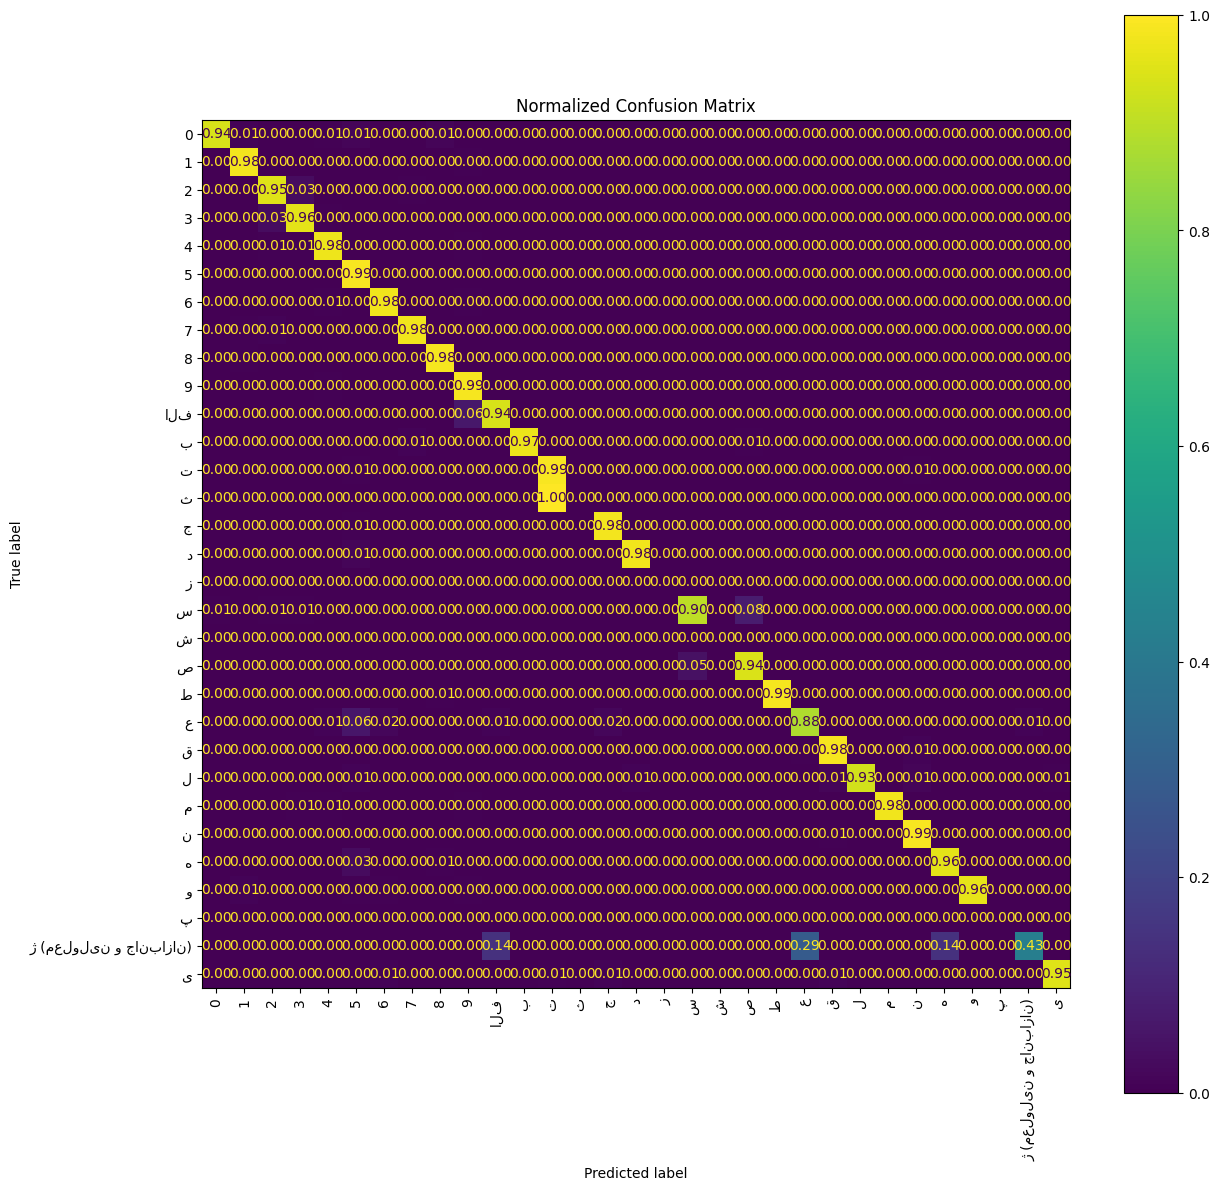

In [100]:
cm_normalized = confusion_matrix(
    y_test,
    predicted_labels,
    labels=classes,
    normalize="true"
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_normalized,
    display_labels=classes
)

fig, ax = plt.subplots(figsize=(14, 14))

disp.plot(
    ax=ax,
    xticks_rotation=90,
    colorbar=True,
    values_format=".2f"
)

plt.title("Normalized Confusion Matrix")
plt.show()

Saving our model

In [103]:
model.save("../models/license_plate_character_cnn.keras")

Save class mapping

In [105]:
with open("../models/class_mapping.json", "w", encoding="utf-8") as f:
    json.dump(
        index_to_class,
        f,
        ensure_ascii=False,
        indent=4
    )